In [1]:
import open3d as o3d

forward = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_forward_002.ply"
)

inverse = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_inverse_002.ply"
)

print("Opening FORWARD...")
print(
    [forward]
)

print("Opening INVERSE...")
print(
    [inverse]
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Opening FORWARD...
[PointCloud with 1051370 points.]
Opening INVERSE...
[PointCloud with 1049037 points.]


RGB frames: 2091
Depth frames: 2091
Pose shape: (2091, 7)
First pose: [ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
  0.77898699]
Last pose: [ 0.83689678  0.13889173  0.09456147  0.01609126 -0.24859226 -0.08068334
  0.9651078 ]

Image sizes:
RGB: (960, 720)
Depth: (256, 192)

Provisional depth intrinsics:
fx, fy, cx, cy = 200.0 200.0 96.0 127.712

Raw depth percentiles:
[ 12.  31.  94. 146. 193. 231. 245.]

Depth-unit decision:
The notebook shows raw depth values from approximately 0 to 255.
The default below interprets them as normalized 8-bit-like depth and
maps 255 units to 5 metres.

This is only a provisional conversion. If you know the real sensor
scale, replace DEPTH_MAX_RAW and ROOM_MAX_METERS below.

Using provisional depth scale:
raw depth / 51.0 = metres

Frames selected: 210
Frame range: 0 to 2090
Processed frame 0000 | points: 48,840 | camera: [ 0.05893505  0.12546577 -0.89114189]


Processed frame 0200 | points: 48,971 | camera: [-0.35580382  0.15011652 -0.94076014]


Processed frame 0400 | points: 48,796 | camera: [-0.66846758  0.15119903 -0.97816992]


Processed frame 0600 | points: 48,848 | camera: [-0.89080703  0.14973596 -1.35309875]


Processed frame 0800 | points: 49,013 | camera: [-0.96077818  0.14324503 -0.89944601]


...

World range: [11.85876102  5.34349525 11.93431972]



After robust spatial filtering:
Points: 9,976,065


Min: [-5.26271717 -1.48856194 -5.6741181 ]


Max: [4.88806401 2.55745049 4.73172951]



Final point cloud:
Points: 5,441,387
Saved: D:/VLM-maps/outputs/reconstruction_outputs\fused_world_pointcloud_2cm.ply


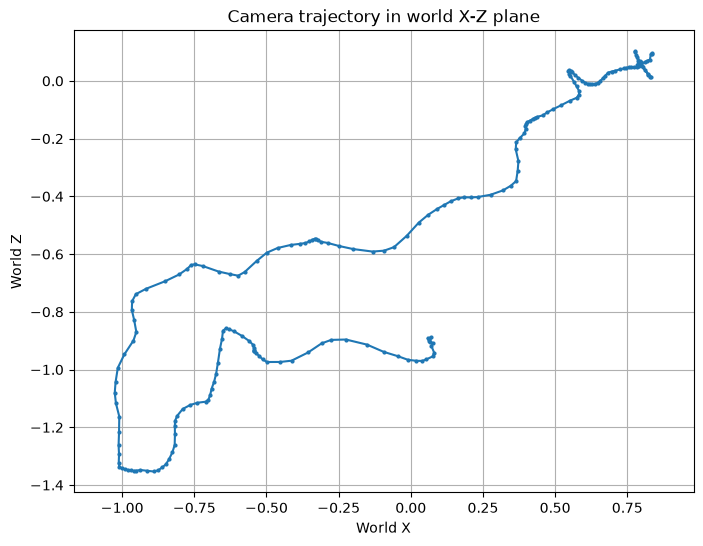

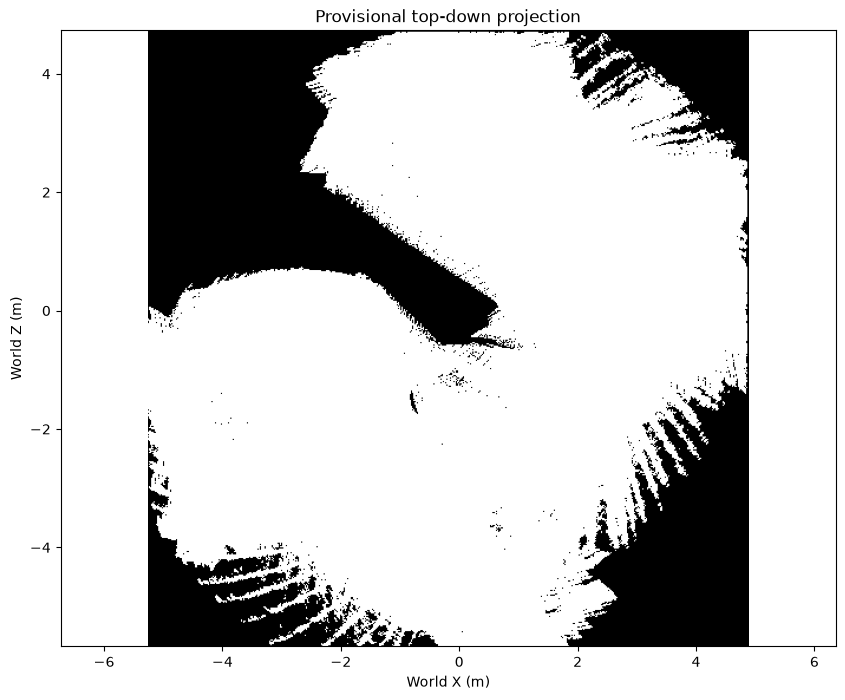

Top-down image saved: D:/VLM-maps/outputs/reconstruction_outputs\provisional_topdown.png
Metadata saved: D:/VLM-maps/outputs/reconstruction_outputs\reconstruction_metadata.json


In [2]:
# ============================================================
# COMPLETE RGB-D POINT-CLOUD FUSION + TOP-DOWN MAP
# ============================================================

import os
import json
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from PIL import Image
from scipy.spatial.transform import Rotation


# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

OUTPUT_DIR = "D:/VLM-maps/outputs/reconstruction_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Load and sort files
# ------------------------------------------------------------

def numeric_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    digits = "".join(ch for ch in stem if ch.isdigit())
    return int(digits) if digits else -1


rgb_files = sorted(
    [
        os.path.join(RGB_DIR, f)
        for f in os.listdir(RGB_DIR)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ],
    key=numeric_stem
)

depth_files = sorted(
    [
        os.path.join(DEPTH_DIR, f)
        for f in os.listdir(DEPTH_DIR)
        if f.lower().endswith(".npy")
    ],
    key=numeric_stem
)

poses = np.loadtxt(POSES_FILE, dtype=np.float64)

assert len(rgb_files) == len(depth_files), (
    f"RGB/depth count mismatch: {len(rgb_files)} vs {len(depth_files)}"
)

assert poses.ndim == 2 and poses.shape[1] == 7, (
    f"Expected poses with shape (N, 7), received {poses.shape}"
)

assert len(poses) == len(rgb_files), (
    f"Pose/frame mismatch: {len(poses)} poses vs {len(rgb_files)} frames"
)

print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))
print("Pose shape:", poses.shape)
print("First pose:", poses[0])
print("Last pose:", poses[-1])


# ------------------------------------------------------------
# 3. Camera parameters
# ------------------------------------------------------------

# These are the values currently present in your notebook.
# They are treated as provisional RGB calibration values.
FX_RGB = 750.0
FY_RGB = 750.0
CX_RGB = 360.0
CY_RGB = 478.92

# Your depth arrays are 256 x 192, according to the notebook.
sample_depth = np.load(depth_files[0])
DEPTH_H, DEPTH_W = sample_depth.shape

sample_rgb = np.asarray(Image.open(rgb_files[0]))
RGB_H, RGB_W = sample_rgb.shape[:2]

# Provisional scaled intrinsics.
# These are valid only if the supplied calibration corresponds to
# the full RGB image and the depth projection has the same geometry.
FX = FX_RGB * DEPTH_W / RGB_W
FY = FY_RGB * DEPTH_H / RGB_H
CX = CX_RGB * DEPTH_W / RGB_W
CY = CY_RGB * DEPTH_H / RGB_H

print("\nImage sizes:")
print("RGB:", (RGB_H, RGB_W))
print("Depth:", (DEPTH_H, DEPTH_W))

print("\nProvisional depth intrinsics:")
print("fx, fy, cx, cy =", FX, FY, CX, CY)


# ------------------------------------------------------------
# 4. Depth-unit diagnostics
# ------------------------------------------------------------

raw_depth_values = []

for path in depth_files[::max(1, len(depth_files) // 30)]:
    d = np.asarray(np.load(path), dtype=np.float32)
    finite = d[np.isfinite(d) & (d > 0)]
    if finite.size:
        raw_depth_values.append(finite)

raw_depth_values = np.concatenate(raw_depth_values)

depth_percentiles = np.percentile(
    raw_depth_values,
    [1, 5, 25, 50, 75, 95, 99]
)

print("\nRaw depth percentiles:")
print(depth_percentiles)

print(
    """
Depth-unit decision:
The notebook shows raw depth values from approximately 0 to 255.
The default below interprets them as normalized 8-bit-like depth and
maps 255 units to 5 metres.

This is only a provisional conversion. If you know the real sensor
scale, replace DEPTH_MAX_RAW and ROOM_MAX_METERS below.
"""
)

DEPTH_MAX_RAW = 255.0
ROOM_MAX_METERS = 5.0

DEPTH_SCALE = DEPTH_MAX_RAW / ROOM_MAX_METERS

print("Using provisional depth scale:")
print("raw depth /", DEPTH_SCALE, "= metres")


# ------------------------------------------------------------
# 5. Pose conversion
# ------------------------------------------------------------

def pose_to_matrix_camera_to_world(pose_row):
    """
    Expected pose format:
        tx ty tz qx qy qz qw

    Assumption:
        quaternion gives camera orientation in world coordinates,
        therefore R maps camera-frame points to world-frame points.
    """
    tx, ty, tz, qx, qy, qz, qw = pose_row

    quaternion = np.array([qx, qy, qz, qw], dtype=np.float64)
    R_camera_to_world = Rotation.from_quat(quaternion).as_matrix()

    T_camera_to_world = np.eye(4, dtype=np.float64)
    T_camera_to_world[:3, :3] = R_camera_to_world
    T_camera_to_world[:3, 3] = [tx, ty, tz]

    return T_camera_to_world


def transform_points(points_camera, T_camera_to_world):
    points_h = np.column_stack(
        [
            points_camera,
            np.ones(len(points_camera), dtype=np.float64)
        ]
    )

    points_world_h = (T_camera_to_world @ points_h.T).T
    return points_world_h[:, :3]


# ------------------------------------------------------------
# 6. Back-project depth into camera coordinates
# ------------------------------------------------------------

def depth_to_camera_points(depth_raw):
    depth_raw = np.asarray(depth_raw, dtype=np.float32)

    # Convert provisional raw depth representation to metres.
    depth_m = depth_raw / DEPTH_SCALE

    valid = (
        np.isfinite(depth_m)
        & (depth_m > 0.15)
        & (depth_m < 6.0)
    )

    v, u = np.indices(depth_m.shape)
    z = depth_m[valid]

    x = (u[valid] - CX) * z / FX
    y = (v[valid] - CY) * z / FY

    points_camera = np.column_stack([x, y, z])

    return points_camera, valid, depth_m


# ------------------------------------------------------------
# 7. RGB handling
# ------------------------------------------------------------

def load_colors(rgb_path, valid_mask):
    """
    This resize is only for provisional visualization.
    It is not true RGB-depth registration.
    """
    rgb = np.asarray(Image.open(rgb_path).convert("RGB"))

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR
        )
    )

    colors = rgb_small[valid_mask].astype(np.float32) / 255.0
    return colors


# ------------------------------------------------------------
# 8. Select frames
# ------------------------------------------------------------

# Start with a manageable sequence.
# After diagnostics pass, change this to np.arange(len(rgb_files)).
FRAME_STEP = 10
frame_indices = np.arange(0, len(rgb_files), FRAME_STEP)

print("\nFrames selected:", len(frame_indices))
print("Frame range:", frame_indices[0], "to", frame_indices[-1])


# ------------------------------------------------------------
# 9. Fuse all frames into world coordinates
# ------------------------------------------------------------

all_world_points = []
all_colors = []
camera_centers = []

for count, frame_idx in enumerate(frame_indices):
    depth_raw = np.load(depth_files[frame_idx]).astype(np.float32)

    points_camera, valid_mask, depth_m = depth_to_camera_points(
        depth_raw
    )

    if len(points_camera) == 0:
        print("Skipping frame", frame_idx, "- no valid depth")
        continue

    T_camera_to_world = pose_to_matrix_camera_to_world(
        poses[frame_idx]
    )

    points_world = transform_points(
        points_camera,
        T_camera_to_world
    )

    colors = load_colors(
        rgb_files[frame_idx],
        valid_mask
    )

    all_world_points.append(points_world)
    all_colors.append(colors)

    camera_centers.append(T_camera_to_world[:3, 3])

    if count % 20 == 0:
        print(
            f"Processed frame {frame_idx:04d} | "
            f"points: {len(points_world):,} | "
            f"camera: {T_camera_to_world[:3, 3]}"
        )


if not all_world_points:
    raise RuntimeError("No valid world points were generated.")

all_world_points = np.vstack(all_world_points)
all_colors = np.vstack(all_colors)
camera_centers = np.vstack(camera_centers)

print("\nRaw fused points:", f"{len(all_world_points):,}")
print("World min:", all_world_points.min(axis=0))
print("World max:", all_world_points.max(axis=0))
print("World range:", np.ptp(all_world_points, axis=0))


# ------------------------------------------------------------
# 10. Remove obvious world-coordinate outliers
# ------------------------------------------------------------

finite_world = np.isfinite(all_world_points).all(axis=1)

all_world_points = all_world_points[finite_world]
all_colors = all_colors[finite_world]

# Robust spatial filtering using percentiles.
# This removes extreme pose/depth failures without deleting normal walls.
low = np.percentile(all_world_points, 0.5, axis=0)
high = np.percentile(all_world_points, 99.5, axis=0)

inside = np.all(
    (all_world_points >= low)
    & (all_world_points <= high),
    axis=1
)

all_world_points = all_world_points[inside]
all_colors = all_colors[inside]

print("\nAfter robust spatial filtering:")
print("Points:", f"{len(all_world_points):,}")
print("Min:", all_world_points.min(axis=0))
print("Max:", all_world_points.max(axis=0))


# ------------------------------------------------------------
# 11. Open3D point cloud
# ------------------------------------------------------------

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(all_world_points)
pcd.colors = o3d.utility.Vector3dVector(all_colors)

# Statistical outlier removal.
# Reduce this if the room is sparse.
pcd, keep_indices = pcd.remove_statistical_outlier(
    nb_neighbors=20,
    std_ratio=2.0
)

# Indoor reconstruction voxel size: 2 cm.
pcd = pcd.voxel_down_sample(voxel_size=0.02)

pcd_path = os.path.join(
    OUTPUT_DIR,
    "fused_world_pointcloud_2cm.ply"
)

o3d.io.write_point_cloud(pcd_path, pcd)

print("\nFinal point cloud:")
print("Points:", f"{len(pcd.points):,}")
print("Saved:", pcd_path)


# ------------------------------------------------------------
# 12. Save camera trajectory
# ------------------------------------------------------------

trajectory_path = os.path.join(
    OUTPUT_DIR,
    "camera_centers.npy"
)

np.save(trajectory_path, camera_centers)


# ------------------------------------------------------------
# 13. Diagnose pose trajectory
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))
plt.plot(
    camera_centers[:, 0],
    camera_centers[:, 2],
    "-o",
    markersize=2
)
plt.xlabel("World X")
plt.ylabel("World Z")
plt.title("Camera trajectory in world X-Z plane")
plt.axis("equal")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 14. Create provisional top-down projection
# ------------------------------------------------------------

points = np.asarray(pcd.points)

# Assumes world Y is vertical and X-Z is the floor plane.
# If your trajectory plot is incorrect, this axis assumption must be changed.
x = points[:, 0]
z = points[:, 2]

TOPDOWN_RESOLUTION = 0.02  # metres per pixel

xmin, xmax = x.min(), x.max()
zmin, zmax = z.min(), z.max()

width = int(np.ceil((xmax - xmin) / TOPDOWN_RESOLUTION)) + 1
height = int(np.ceil((zmax - zmin) / TOPDOWN_RESOLUTION)) + 1

ix = np.floor(
    (x - xmin) / TOPDOWN_RESOLUTION
).astype(np.int32)

iz = np.floor(
    (z - zmin) / TOPDOWN_RESOLUTION
).astype(np.int32)

valid_grid = (
    (ix >= 0) & (ix < width)
    & (iz >= 0) & (iz < height)
)

ix = ix[valid_grid]
iz = iz[valid_grid]

topdown = np.zeros((height, width), dtype=np.uint8)
topdown[height - 1 - iz, ix] = 255

topdown_path = os.path.join(
    OUTPUT_DIR,
    "provisional_topdown.png"
)

Image.fromarray(topdown).save(topdown_path)

plt.figure(figsize=(10, 8))
plt.imshow(
    topdown,
    cmap="gray",
    origin="upper",
    extent=[xmin, xmax, zmin, zmax]
)
plt.xlabel("World X (m)")
plt.ylabel("World Z (m)")
plt.title("Provisional top-down projection")
plt.axis("equal")
plt.show()

print("Top-down image saved:", topdown_path)


# ------------------------------------------------------------
# 15. Save reconstruction metadata
# ------------------------------------------------------------

metadata = {
    "num_rgb_frames": len(rgb_files),
    "num_depth_frames": len(depth_files),
    "num_poses": len(poses),
    "selected_frames": len(frame_indices),
    "frame_step": int(FRAME_STEP),
    "depth_raw_percentiles": depth_percentiles.tolist(),
    "depth_max_raw": float(DEPTH_MAX_RAW),
    "room_max_meters": float(ROOM_MAX_METERS),
    "depth_scale_raw_units_per_meter": float(DEPTH_SCALE),
    "depth_intrinsics": {
        "fx": float(FX),
        "fy": float(FY),
        "cx": float(CX),
        "cy": float(CY),
    },
    "voxel_size_m": 0.02,
    "topdown_resolution_m": TOPDOWN_RESOLUTION,
    "pose_format": "tx ty tz qx qy qz qw",
    "pose_assumption": "camera-to-world",
    "vertical_axis_assumption": "world Y",
    "topdown_axes": "world X-Z",
    "rgb_depth_alignment": "provisional resize only",
}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "reconstruction_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Metadata saved:", metadata_path)